# PART 1

In [2]:
import pandas as pd

files = {
    "orders": "olist_orders_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "translation": "product_category_name_translation.csv",
}

tables = {}
for name, filename in files.items():
    tables[name] = pd.read_csv("../data/" + filename)
    print(name, "→ rows, columns:", tables[name].shape)

orders → rows, columns: (99441, 8)
customers → rows, columns: (99441, 5)
items → rows, columns: (112650, 7)
payments → rows, columns: (103886, 5)
reviews → rows, columns: (99224, 7)
products → rows, columns: (32951, 9)
sellers → rows, columns: (3095, 4)
geolocation → rows, columns: (1000163, 5)
translation → rows, columns: (71, 2)


### Part A: Audit sheet (one summary table)

In [3]:
audit = []
for name, df in tables.items():
    audit.append({
        "table": name,
        "rows": df.shape[0],
        "columns": df.shape[1],
        "missing_cells": int(df.isna().sum().sum()),
        "duplicate_rows": int(df.duplicated().sum()),
    })

audit_df = pd.DataFrame(audit)
audit_df

,table,rows,columns,missing_cells,duplicate_rows
0,orders,99441,8,4908,0
1,customers,99441,5,0,0
2,items,112650,7,0,0
3,payments,103886,5,0,0
4,reviews,99224,7,145903,0
5,products,32951,9,2448,0
6,sellers,3095,4,0,0
7,geolocation,1000163,5,0,261831
8,translation,71,2,0,0


### Part B: Which columns have missing values?

In [4]:
for name in ["orders", "products", "reviews"]:
    print("-----", name)
    print(tables[name].isna().sum())

----- orders
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64
----- products
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64
----- reviews
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64


### Part C: Are the ID columns unique?

In [5]:
print("orders: order_id unique?", tables["orders"]["order_id"].is_unique)
print("customers: customer_id unique?", tables["customers"]["customer_id"].is_unique)
print("products: product_id unique?", tables["products"]["product_id"].is_unique)
print("sellers: seller_id unique?", tables["sellers"]["seller_id"].is_unique)

print("items: repeated (order_id + order_item_id):",
      tables["items"].duplicated(subset=["order_id", "order_item_id"]).sum())

print("reviews: repeated review_id:", tables["reviews"]["review_id"].duplicated().sum())
print("reviews: repeated order_id:", tables["reviews"]["order_id"].duplicated().sum())

orders: order_id unique? True
customers: customer_id unique? True
products: product_id unique? True
sellers: seller_id unique? True
items: repeated (order_id + order_item_id): 0
reviews: repeated review_id: 814
reviews: repeated order_id: 551


### Part D: Fix the date columns and see the date range

In [6]:
orders = tables["orders"].copy()

date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

for c in date_cols:
    orders[c] = pd.to_datetime(orders[c])

orders[date_cols].agg(["min", "max"]).T

,min,max
order_purchase_timestamp,2016-09-04 21:15:19,2018-10-17 17:30:18
order_approved_at,2016-09-15 12:16:38,2018-09-03 17:40:06
order_delivered_carrier_date,2016-10-08 10:34:01,2018-09-11 19:48:28
order_delivered_customer_date,2016-10-11 13:46:32,2018-10-17 13:22:46
order_estimated_delivery_date,2016-09-30 00:00:00,2018-11-12 00:00:00


### Part E: What are the order statuses?

In [7]:
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

### Part F: Do the dates make sense?

In [8]:
print("Delivered BEFORE purchase:",
      (orders["order_delivered_customer_date"] < orders["order_purchase_timestamp"]).sum())

print("Approved BEFORE purchase:",
      (orders["order_approved_at"] < orders["order_purchase_timestamp"]).sum())

print("Delivered to customer BEFORE carrier picked up:",
      (orders["order_delivered_customer_date"] < orders["order_delivered_carrier_date"]).sum())

delivered = orders[orders["order_status"] == "delivered"]
print("Delivered orders with missing delivery date:",
      delivered["order_delivered_customer_date"].isna().sum())

Delivered BEFORE purchase: 0
Approved BEFORE purchase: 0
Delivered to customer BEFORE carrier picked up: 23
Delivered orders with missing delivery date: 8


# PART 2

### PART A

In [9]:
# 1. Keep only orders we can judge
cohort = orders[
    (orders["order_status"] == "delivered")
    & orders["order_delivered_customer_date"].notna()
    & orders["order_estimated_delivery_date"].notna()
].copy()

print("Orders in our group:", len(cohort))
print("Orders left out:", len(orders) - len(cohort))

# 2. Strict way (compares exact time)
cohort["late_strict"] = (
    cohort["order_delivered_customer_date"] > cohort["order_estimated_delivery_date"]
).astype(int)

# 3. Day way (compares only the day) - we will use this one
delivered_day = cohort["order_delivered_customer_date"].dt.normalize()
promised_day = cohort["order_estimated_delivery_date"].dt.normalize()
cohort["is_late"] = (delivered_day > promised_day).astype(int)

print("Late rate (strict way):", round(cohort["late_strict"].mean() * 100, 2), "%")
print("Late rate (day way):   ", round(cohort["is_late"].mean() * 100, 2), "%")
print(cohort["is_late"].value_counts())

Orders in our group: 96470
Orders left out: 2971
Late rate (strict way): 8.11 %
Late rate (day way):    6.77 %
is_late
0    89936
1     6534
Name: count, dtype: int64


### Part B: Look at the late rate month by month

In [10]:
cohort["purchase_month"] = cohort["order_purchase_timestamp"].dt.to_period("M")

monthly = cohort.groupby("purchase_month")["is_late"].agg(["count", "mean"])
monthly["mean"] = (monthly["mean"] * 100).round(2)
monthly.columns = ["orders", "late_percent"]
monthly

,orders,late_percent
purchase_month,,
2016-09,1,100.00
2016-10,265,0.75
2016-12,1,0.00
2017-01,750,2.93
2017-02,1653,2.96
2017-03,2546,4.56
2017-04,2303,6.56
2017-05,3545,2.99
2017-06,3135,3.03


Matplotlib is building the font cache; this may take a moment.


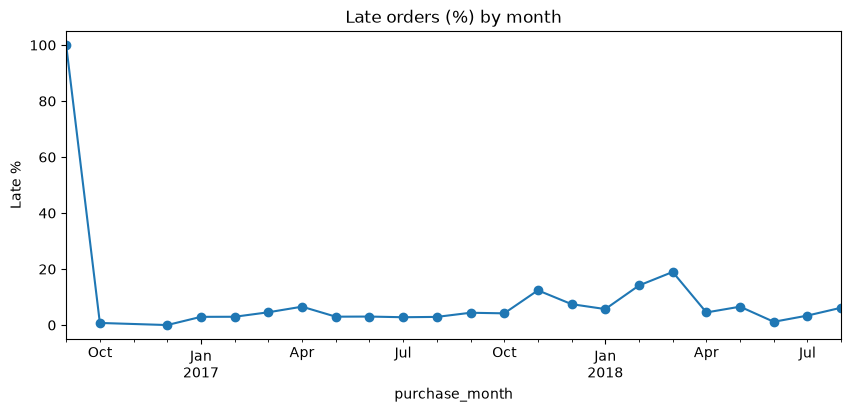

In [11]:
import matplotlib.pyplot as plt

monthly["late_percent"].plot(kind="line", marker="o", figsize=(10, 4))
plt.title("Late orders (%) by month")
plt.ylabel("Late %")
plt.show()

# PART 3 :Understand the business

### Part A: Build a small working table (join safely)

In [12]:
# 1. Customer state
cust = tables["customers"][["customer_id", "customer_state"]]
df = cohort.merge(cust, on="customer_id", how="left", validate="one_to_one")
assert len(df) == len(cohort)

# 2. Summarize items to one row per order
items = tables["items"]
items_agg = items.groupby("order_id").agg(
    n_items=("order_item_id", "count"),
    total_price=("price", "sum"),
    total_freight=("freight_value", "sum"),
    n_sellers=("seller_id", "nunique"),
    main_seller=("seller_id", "first"),
).reset_index()

df = df.merge(items_agg, on="order_id", how="left", validate="one_to_one")
assert len(df) == len(cohort)

# 3. Seller state (of the main seller)
sellers_small = tables["sellers"][["seller_id", "seller_state"]].rename(
    columns={"seller_id": "main_seller"}
)
df = df.merge(sellers_small, on="main_seller", how="left", validate="many_to_one")
assert len(df) == len(cohort)

print("Rows:", len(df))
print("Orders with no items:", df["n_items"].isna().sum())

Rows: 96470
Orders with no items: 0


### Part B: A helper that shows late rate for any column

In [13]:
def late_by(col, min_orders=200):
    t = df.groupby(col, observed=True)["is_late"].agg(["count", "mean"])
    t["mean"] = (t["mean"] * 100).round(2)
    t.columns = ["orders", "late_percent"]
    return t[t["orders"] >= min_orders].sort_values("late_percent", ascending=False)

### Part C: Look at different groups

In [14]:
# Customer state
late_by("customer_state")

# Seller state
late_by("seller_state")

# One seller vs many sellers in an order
late_by("n_sellers", min_orders=50)

# Freight (delivery charge) in 5 equal groups
df["freight_group"] = pd.qcut(df["total_freight"], 5, duplicates="drop")
late_by("freight_group", min_orders=0)

,orders,late_percent
freight_group,,
"(27.38, 1794.96]",19276,8.12
"(18.59, 27.38]",19225,7.68
"(15.64, 18.59]",19380,7.61
"(12.83, 15.64]",19192,6.04
"(-0.001, 12.83]",19397,4.42


### Part D: Reviews (for the story only)

In [15]:
rev = tables["reviews"].groupby("order_id")["review_score"].mean().reset_index()
df_rev = df.merge(rev, on="order_id", how="left", validate="one_to_one")

df_rev.groupby("is_late")["review_score"].mean().round(2)

is_late
0    4.29
1    2.27
Name: review_score, dtype: float64

### Part E: Three pictures

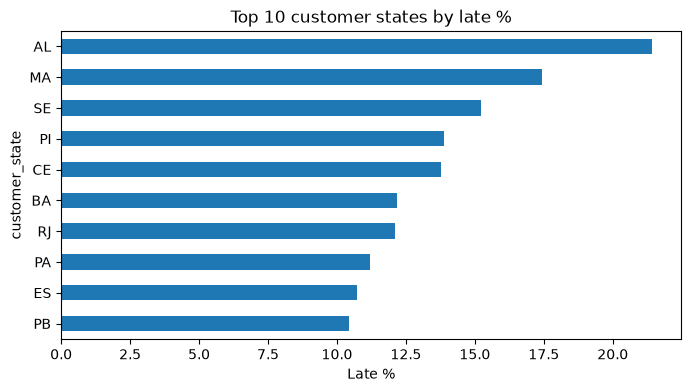

,count,mean,std,min,25%,50%,75%,max
is_late,,,,,,,,
0,89936.0,10.539261,6.323296,0.0,6.0,9.0,14.0,70.0
1,6534.0,33.488062,17.482556,3.0,24.0,31.0,40.0,209.0


In [16]:
import matplotlib.pyplot as plt

late_by("customer_state").head(10)["late_percent"].sort_values().plot(
    kind="barh", figsize=(8, 4), title="Top 10 customer states by late %"
)
plt.xlabel("Late %")
plt.show()

df["delivery_days"] = (
    df["order_delivered_customer_date"] - df["order_purchase_timestamp"]
).dt.days
df.groupby("is_late")["delivery_days"].describe()

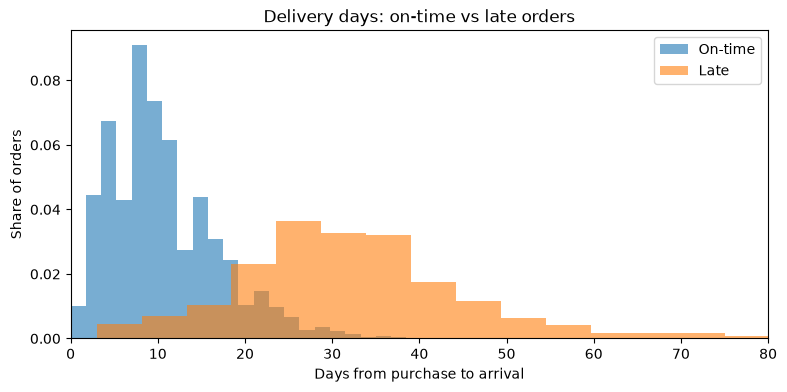

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4))

plt.hist(df.loc[df["is_late"] == 0, "delivery_days"],
         bins=40, alpha=0.6, density=True, label="On-time")
plt.hist(df.loc[df["is_late"] == 1, "delivery_days"],
         bins=40, alpha=0.6, density=True, label="Late")

plt.xlim(0, 80)
plt.title("Delivery days: on-time vs late orders")
plt.xlabel("Days from purchase to arrival")
plt.ylabel("Share of orders")
plt.legend()
plt.show()

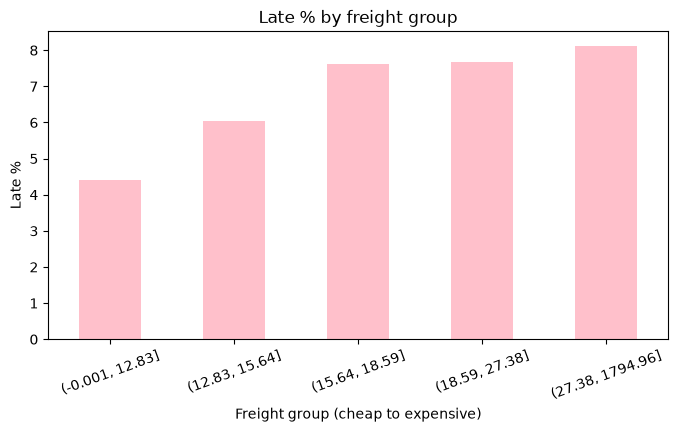

In [19]:
late_by("freight_group", min_orders=0).sort_index()["late_percent"].plot(
    kind="bar", figsize=(8, 4), title="Late % by freight group",color="Pink"
)
plt.xlabel("Freight group (cheap to expensive)")
plt.ylabel("Late %")
plt.xticks(rotation=20)
plt.show()

# STEP 4: Build the master table

### Part A: Start the master table

In [20]:
master = cohort[[
    "order_id", "customer_id",
    "order_purchase_timestamp",
    "order_estimated_delivery_date",
    "is_late",
]].copy()

cust = tables["customers"][["customer_id", "customer_zip_code_prefix", "customer_state"]]
master = master.merge(cust, on="customer_id", how="left", validate="one_to_one")
assert len(master) == len(cohort)
print("Rows:", len(master))

Rows: 96470


### Part B: Summarize the items

In [21]:
items = tables["items"].sort_values(["order_id", "order_item_id"]).copy()
items["shipping_limit_date"] = pd.to_datetime(items["shipping_limit_date"])

items_agg = items.groupby("order_id").agg(
    n_items=("order_item_id", "count"),
    total_price=("price", "sum"),
    total_freight=("freight_value", "sum"),
    n_sellers=("seller_id", "nunique"),
    n_products=("product_id", "nunique"),
    main_seller=("seller_id", "first"),
    first_limit=("shipping_limit_date", "min"),
    last_limit=("shipping_limit_date", "max"),
).reset_index()

master = master.merge(items_agg, on="order_id", how="left", validate="one_to_one")
assert len(master) == len(cohort)
print("Rows:", len(master))

Rows: 96470


### Part C: Summarize the products (weight and size)

In [22]:
prod = tables["products"].copy()
prod["volume_cm3"] = (
    prod["product_length_cm"] * prod["product_height_cm"] * prod["product_width_cm"]
)

it = items.merge(
    prod[["product_id", "product_category_name", "product_weight_g", "volume_cm3"]],
    on="product_id", how="left", validate="many_to_one",
)
assert len(it) == len(items)

prod_agg = it.groupby("order_id").agg(
    total_weight_g=("product_weight_g", lambda s: s.sum(min_count=1)),
    max_weight_g=("product_weight_g", "max"),
    total_volume_cm3=("volume_cm3", lambda s: s.sum(min_count=1)),
    main_category=("product_category_name", "first"),
).reset_index()

master = master.merge(prod_agg, on="order_id", how="left", validate="one_to_one")
assert len(master) == len(cohort)
print("Rows:", len(master))

Rows: 96470


### Part D: Summarize the payments

In [23]:
pay = tables["payments"].sort_values(["order_id", "payment_sequential"])

pay_agg = pay.groupby("order_id").agg(
    n_payments=("payment_sequential", "count"),
    total_payment=("payment_value", "sum"),
    max_installments=("payment_installments", "max"),
    main_payment_type=("payment_type", "first"),
).reset_index()

master = master.merge(pay_agg, on="order_id", how="left", validate="one_to_one")
assert len(master) == len(cohort)
print("Rows:", len(master))

Rows: 96470


### Part E: Add seller ZIP and state

In [24]:
sel = tables["sellers"][["seller_id", "seller_zip_code_prefix", "seller_state"]].rename(
    columns={"seller_id": "main_seller"}
)
master = master.merge(sel, on="main_seller", how="left", validate="many_to_one")
assert len(master) == len(cohort)
print("Rows:", len(master))

Rows: 96470


### Part F: Map points for ZIP codes (geolocation)

In [25]:
geo = tables["geolocation"]

# Keep only points inside Brazil (remove wrong points)
geo = geo[
    geo["geolocation_lat"].between(-34, 6) & geo["geolocation_lng"].between(-74, -34)
]

geo_c = geo.groupby("geolocation_zip_code_prefix").agg(
    lat=("geolocation_lat", "median"),
    lng=("geolocation_lng", "median"),
).reset_index()

assert geo_c["geolocation_zip_code_prefix"].is_unique
print("ZIP codes with a map point:", len(geo_c))

# Customer point
master = master.merge(
    geo_c.rename(columns={"geolocation_zip_code_prefix": "customer_zip_code_prefix",
                          "lat": "cust_lat", "lng": "cust_lng"}),
    on="customer_zip_code_prefix", how="left", validate="many_to_one",
)
assert len(master) == len(cohort)

# Seller point
master = master.merge(
    geo_c.rename(columns={"geolocation_zip_code_prefix": "seller_zip_code_prefix",
                          "lat": "seller_lat", "lng": "seller_lng"}),
    on="seller_zip_code_prefix", how="left", validate="many_to_one",
)
assert len(master) == len(cohort)
print("Rows:", len(master))

ZIP codes with a map point: 19010
Rows: 96470


### Part G: Final safety checks

In [26]:
print("Shape:", master.shape)
print("Late rate:", round(master["is_late"].mean() * 100, 2), "%")
print("order_id unique?", master["order_id"].is_unique)
print(master.isna().sum()[master.isna().sum() > 0])

forbidden = ["order_delivered_customer_date", "order_delivered_carrier_date",
             "delivery_days", "review_score"]
assert not any(c in master.columns for c in forbidden)
print("No cheating columns found. Good!")

Shape: (96470, 29)
Late rate: 6.77 %
order_id unique? True
total_weight_g         16
max_weight_g           16
total_volume_cm3       16
main_category        1332
n_payments              1
total_payment           1
max_installments        1
main_payment_type       1
cust_lat              265
cust_lng              265
seller_lat            215
seller_lng            215
dtype: int64
No cheating columns found. Good!


# STEP 5: Build the features

### Part A: Simple features

In [27]:
import numpy as np

feat = master.copy()

# 1. Calendar clues (from purchase time)
feat["purchase_month"] = feat["order_purchase_timestamp"].dt.month
feat["purchase_dow"] = feat["order_purchase_timestamp"].dt.dayofweek   # 0 = Monday
feat["purchase_hour"] = feat["order_purchase_timestamp"].dt.hour
feat["is_weekend"] = (feat["purchase_dow"] >= 5).astype(int)

# 2. Promise clue: how many days did Olist promise?
feat["promise_days"] = (
    feat["order_estimated_delivery_date"].dt.normalize()
    - feat["order_purchase_timestamp"].dt.normalize()
).dt.days

# 3. Seller deadline clues
feat["days_to_first_limit"] = (
    feat["first_limit"] - feat["order_purchase_timestamp"]
).dt.total_seconds() / 86400
feat["days_to_last_limit"] = (
    feat["last_limit"] - feat["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Days left for the courier after the seller's last deadline
feat["courier_window_days"] = (
    feat["order_estimated_delivery_date"] - feat["last_limit"]
).dt.total_seconds() / 86400

# 4. Distance between seller and customer (in km)
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

feat["distance_km"] = haversine_km(
    feat["seller_lat"], feat["seller_lng"], feat["cust_lat"], feat["cust_lng"]
)

# 5. Simple flags and ratios
feat["same_state"] = (feat["customer_state"] == feat["seller_state"]).astype(int)
feat["multi_seller"] = (feat["n_sellers"] > 1).astype(int)
feat["freight_ratio"] = feat["total_freight"] / (feat["total_price"] + 1)
feat["density_g_per_cm3"] = feat["total_weight_g"] / feat["total_volume_cm3"]

print("Shape:", feat.shape)

Shape: (96470, 42)


### Part B: Check the new features

In [28]:
new_cols = ["promise_days", "days_to_first_limit", "days_to_last_limit",
            "courier_window_days", "distance_km", "freight_ratio", "density_g_per_cm3"]
print(feat[new_cols].describe().round(2))

print("promise_days <= 0:", (feat["promise_days"] <= 0).sum())
print("days_to_last_limit < 0:", (feat["days_to_last_limit"] < 0).sum())
print("courier_window_days < 0:", (feat["courier_window_days"] < 0).sum())
print("distance_km missing:", feat["distance_km"].isna().sum())
print("Late rate still:", round(feat["is_late"].mean() * 100, 2), "%")

       promise_days  days_to_first_limit  days_to_last_limit  \
count      96470.00             96470.00            96470.00   
mean          24.37                 6.56                6.57   
std            8.76                 4.66                4.66   
min            3.00                 2.00                2.00   
25%           19.00                 5.01                5.01   
50%           24.00                 6.01                6.01   
75%           29.00                 7.12                7.14   
max          156.00              1052.00             1052.00   

       courier_window_days  distance_km  freight_ratio  density_g_per_cm3  
count             96470.00     95991.00       96470.00           96454.00  
mean                 17.16       600.41           0.30               0.19  
std                   8.57       592.43           0.28               0.71  
min                -911.94         0.00           0.00               0.00  
25%                  12.31       184.97    

### PartC: Do these clues really help?

In [30]:
for col in ["distance_km", "promise_days", "courier_window_days"]:
    groups = pd.qcut(feat[col], 5, duplicates="drop")
    t = feat.groupby(groups, observed=True)["is_late"].agg(["count", "mean"])
    t["mean"] = (t["mean"] * 100).round(2)
    t.columns = ["orders", "late_percent"]
    print("-----", col)
    print(t)

print(feat.groupby("same_state")["is_late"].mean().mul(100).round(2))
print(feat.groupby("multi_seller")["is_late"].mean().mul(100).round(2))

----- distance_km
                     orders  late_percent
distance_km                              
(-0.001, 116.048]     19199          4.53
(116.048, 347.942]    19198          5.79
(347.942, 529.71]     19198          6.61
(529.71, 876.365]     19198          7.20
(876.365, 3398.486]   19198          9.67
----- promise_days
               orders  late_percent
promise_days                       
(2.999, 17.0]   19392          6.02
(17.0, 22.0]    21739          8.18
(22.0, 26.0]    20612          7.52
(26.0, 31.0]    17674          7.04
(31.0, 156.0]   17053          4.66
----- courier_window_days
                     orders  late_percent
courier_window_days                      
(-911.942, 10.84]     19294          6.42
(10.84, 14.812]       19294          7.60
(14.812, 18.59]       19294          7.69
(18.59, 23.104]       19294          7.17
(23.104, 147.576]     19294          4.99
same_state
0    8.05
1    4.50
Name: is_late, dtype: float64
multi_seller
0    6.85
1    1.02
Nam

### Part D: The seller’s past record

In [31]:
# 1. Small table with the information we need to build the history
hist = cohort[["order_id", "order_delivered_customer_date", "is_late"]].rename(
    columns={"order_delivered_customer_date": "delivered_at"}
)
base = feat[["order_id", "main_seller", "order_purchase_timestamp"]].merge(
    hist, on="order_id", how="left", validate="one_to_one"
)

# 2. For each seller, count earlier orders that were already delivered
results = []
for seller, g in base.groupby("main_seller"):
    ev = g.sort_values("delivered_at")
    d = ev["delivered_at"].values
    cum_late = np.concatenate([[0], np.cumsum(ev["is_late"].values)])

    idx = np.searchsorted(d, g["order_purchase_timestamp"].values, side="left")

    results.append(pd.DataFrame({
        "order_id": g["order_id"].values,
        "seller_prev_orders": idx,
        "seller_prev_late": cum_late[idx],
    }))

hist_feat = pd.concat(results, ignore_index=True)

# 3. Add to the feature table
feat = feat.merge(hist_feat, on="order_id", how="left", validate="one_to_one")
assert len(feat) == len(cohort)

# 4. Smoothed late rate (so a seller with 2 orders is not trusted too much)
prior_rate = 0.07
k = 10
feat["seller_late_rate_smooth"] = (
    (feat["seller_prev_late"] + k * prior_rate) / (feat["seller_prev_orders"] + k)
)

# 5. The "km per promised day" clue
feat["km_per_promised_day"] = feat["distance_km"] / feat["promise_days"]

print("Shape:", feat.shape)

Shape: (96470, 46)


#### Safety checks (leakage tests)

In [32]:
total_by_seller = feat.groupby("main_seller")["order_id"].transform("count")
assert (feat["seller_prev_orders"] <= total_by_seller - 1).all()
print("Check passed: history never uses the order itself.")

print("Orders with no seller history:",
      round((feat["seller_prev_orders"] == 0).mean() * 100, 1), "%")

Check passed: history never uses the order itself.
Orders with no seller history: 5.5 %


#### Do the new clues help?

In [33]:
sub = feat[feat["seller_prev_orders"] >= 20]
groups = pd.qcut(sub["seller_late_rate_smooth"], 5, duplicates="drop")
t = sub.groupby(groups, observed=True)["is_late"].agg(["count", "mean"])
t["mean"] = (t["mean"] * 100).round(2)
t.columns = ["orders", "late_percent"]
print(t)

groups2 = pd.qcut(feat["km_per_promised_day"], 5, duplicates="drop")
t2 = feat.groupby(groups2, observed=True)["is_late"].agg(["count", "mean"])
t2["mean"] = (t2["mean"] * 100).round(2)
t2.columns = ["orders", "late_percent"]
print(t2)

                                 orders  late_percent
seller_late_rate_smooth                              
(0.0022299999999999998, 0.0212]   13217          5.46
(0.0212, 0.0353]                  12887          6.27
(0.0353, 0.05]                    13084          7.18
(0.05, 0.0758]                    13047          8.10
(0.0758, 0.413]                   13021          7.85
                     orders  late_percent
km_per_promised_day                      
(-0.001, 6.532]       19199          3.88
(6.532, 14.748]       19198          5.01
(14.748, 21.987]      19198          7.05
(21.987, 33.981]      19198          7.42
(33.981, 231.911]     19198         10.44


#### Code: how many orders have more than one seller?

In [34]:
summary = feat.groupby("multi_seller")["is_late"].agg(
    orders="count",
    late_orders="sum",
    late_percent=lambda s: round(s.mean() * 100, 2),
)
summary.index = ["One seller (0)", "Many sellers (1)"]
summary

,orders,late_orders,late_percent
One seller (0),95195,6521,6.85
Many sellers (1),1275,13,1.02


# STEP 6:Split the data by time

### Part A: Save your work first

In [35]:
feat.to_pickle("../data/feat.pkl")

### Part B: Make the split

In [36]:
model_df = feat[feat["order_purchase_timestamp"] >= "2017-01-01"].copy()
print("Left out (2016):", len(feat) - len(model_df))

t = model_df["order_purchase_timestamp"]
train = model_df[t < "2018-01-01"].copy()
valid = model_df[(t >= "2018-01-01") & (t < "2018-05-01")].copy()
test  = model_df[t >= "2018-05-01"].copy()

# Safety checks
assert len(train) + len(valid) + len(test) == len(model_df)
assert train["order_purchase_timestamp"].max() < valid["order_purchase_timestamp"].min()
assert valid["order_purchase_timestamp"].max() < test["order_purchase_timestamp"].min()
assert not set(train["order_id"]) & set(valid["order_id"])
assert not set(valid["order_id"]) & set(test["order_id"])

summary = pd.DataFrame({
    "orders": [len(train), len(valid), len(test)],
    "first_date": [d["order_purchase_timestamp"].min().date() for d in (train, valid, test)],
    "last_date": [d["order_purchase_timestamp"].max().date() for d in (train, valid, test)],
    "late_percent": [round(d["is_late"].mean() * 100, 2) for d in (train, valid, test)],
}, index=["train", "valid", "test"])
summary

Left out (2016): 267


,orders,first_date,last_date,late_percent
train,43426,2017-01-05,2017-12-31,5.65
valid,27425,2018-01-01,2018-04-30,10.80
test,25352,2018-05-01,2018-08-29,4.40


### Part C: Fix the small cheating risk in the seller rate

In [37]:
k = 10
prior_rate = train["is_late"].mean()
print("Prior rate from train only:", round(prior_rate, 4))

for d in (train, valid, test):
    d["seller_late_rate_smooth"] = (
        (d["seller_prev_late"] + k * prior_rate) / (d["seller_prev_orders"] + k)
    )

Prior rate from train only: 0.0565


### Part D: Choose the clues and the answer

In [38]:
numeric_features = [
    "purchase_month", "purchase_dow", "purchase_hour", "is_weekend",
    "promise_days", "days_to_first_limit", "days_to_last_limit", "courier_window_days",
    "distance_km", "km_per_promised_day", "same_state", "multi_seller",
    "freight_ratio", "density_g_per_cm3",
    "seller_prev_orders", "seller_prev_late", "seller_late_rate_smooth",
    "n_items", "n_products", "n_sellers", "total_price", "total_freight",
    "total_weight_g", "max_weight_g", "total_volume_cm3",
    "n_payments", "total_payment", "max_installments",
]
categorical_features = ["customer_state", "seller_state", "main_category", "main_payment_type"]
target = "is_late"

features = numeric_features + categorical_features

forbidden = ["order_delivered_customer_date", "order_delivered_carrier_date",
             "delivery_days", "review_score", "delivered_at"]
assert not any(c in features for c in forbidden)
print("Number of clues:", len(features))

X_train, y_train = train[features], train[target]
X_valid, y_valid = valid[features], valid[target]
X_test,  y_test  = test[features],  test[target]

Number of clues: 32


# ------------------------------------BREAK1----------------------------------------

## SAVING THE DATA FOR TOMMOROW

In [39]:
import json

train.to_pickle("../data/train.pkl")
valid.to_pickle("../data/valid.pkl")
test.to_pickle("../data/test.pkl")

with open("../data/feature_list.json", "w") as f:
    json.dump({
        "numeric": numeric_features,
        "categorical": categorical_features,
        "target": target,
    }, f)

print("Saved!")

Saved!


In [1]:
import pandas as pd
import numpy as np
import json

train = pd.read_pickle("../data/train.pkl")
valid = pd.read_pickle("../data/valid.pkl")
test = pd.read_pickle("../data/test.pkl")

with open("../data/feature_list.json") as f:
    cfg = json.load(f)

numeric_features = cfg["numeric"]
categorical_features = cfg["categorical"]
target = cfg["target"]
features = numeric_features + categorical_features

X_train, y_train = train[features], train[target]
X_valid, y_valid = valid[features], valid[target]
X_test, y_test = test[features], test[target]

print(train.shape, valid.shape, test.shape, len(features))

(43426, 46) (27425, 46) (25352, 46) 32


# STEP 7: Baseline models

In [2]:
feat = pd.read_pickle("../data/feat.pkl")
print(feat.shape)

(96470, 46)


### Part A: Build the cleaning pipeline

In [3]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

class Winsorizer(BaseEstimator, TransformerMixin):
    """Caps extreme values. Limits are learned from the training data only."""
    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.low_ = np.nanquantile(X, self.lower, axis=0)
        self.high_ = np.nanquantile(X, self.upper, axis=0)
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        return np.clip(X, self.low_, self.high_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

numeric_pipe = Pipeline([
    ("cap", Winsorizer()),
    ("fill", SimpleImputer(strategy="median", add_indicator=True)),
    ("scale", StandardScaler()),
])

categorical_pipe = Pipeline([
    ("fill", SimpleImputer(strategy="constant", fill_value="unknown")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=100)),
])

preprocess = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features),
])

### Part B: Make the judging tool

In [4]:
from sklearn.metrics import average_precision_score, roc_auc_score

def evaluate(name, model, X, y, top_share=0.10):
    p = model.predict_proba(X)[:, 1]
    n_top = int(len(y) * top_share)
    order = np.argsort(-p)
    top = y.values[order[:n_top]]
    return {
        "model": name,
        "late_rate": round(y.mean(), 4),
        "PR-AUC": round(average_precision_score(y, p), 4),
        "ROC-AUC": round(roc_auc_score(y, p), 4),
        "precision@top10%": round(top.mean(), 4),
        "recall@top10%": round(top.sum() / y.sum(), 4),
    }

### Part C: Lazy model and Logistic Regression

In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

# 1. Lazy model
dummy = DummyClassifier(strategy="prior")
dummy.fit(X_train, y_train)

# 2. Logistic Regression with the cleaning pipeline
logreg = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(max_iter=2000, class_weight="balanced")),
])
logreg.fit(X_train, y_train)

results = pd.DataFrame([
    evaluate("Dummy (valid)", dummy, X_valid, y_valid),
    evaluate("LogReg (train)", logreg, X_train, y_train),
    evaluate("LogReg (valid)", logreg, X_valid, y_valid),
])
results

,model,late_rate,PR-AUC,ROC-AUC,precision@top10%,recall@top10%
0,Dummy (valid),0.1080,0.1080,0.5000,0.1050,0.0972
1,LogReg (train),0.0565,0.1491,0.7191,0.1817,0.3216
2,LogReg (valid),0.1080,0.2312,0.6993,0.2859,0.2646


# STEP 8: Stronger models

### Part A: Random Forest

In [6]:
from sklearn.ensemble import RandomForestClassifier

rf = Pipeline([
    ("prep", preprocess),
    ("model", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=50,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42,
    )),
])
rf.fit(X_train, y_train)

res_rf = evaluate("RandomForest (valid)", rf, X_valid, y_valid)
res_rf

{'model': 'RandomForest (valid)',
 'late_rate': np.float64(0.108),
 'PR-AUC': 0.2043,
 'ROC-AUC': 0.6679,
 'precision@top10%': np.float64(0.2557),
 'recall@top10%': np.float64(0.2366)}

### Part B: LightGBM (3 settings)

In [8]:
%pip install lightgbm

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   --------------- ------------------------ 0.5/1.4 MB 1.7 MB/s eta 0:00:01
   ----------------------- ---------------- 0.8/1.4 MB 1.3 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 1.8 MB/s  0:00:01
Note: you may need to restart the kernel to use updated packages.


In [9]:
from lightgbm import LGBMClassifier

configs = {
    "LGBM small":  dict(n_estimators=300, learning_rate=0.03, num_leaves=15),
    "LGBM medium": dict(n_estimators=400, learning_rate=0.03, num_leaves=31),
    "LGBM large":  dict(n_estimators=600, learning_rate=0.02, num_leaves=63),
}

lgbm_models = {}
lgbm_results = []

for name, params in configs.items():
    model = Pipeline([
        ("prep", preprocess),
        ("model", LGBMClassifier(
            min_child_samples=100,
            subsample=0.8, subsample_freq=1,
            colsample_bytree=0.8,
            random_state=42, n_jobs=-1, verbose=-1,
            **params,
        )),
    ])
    model.fit(X_train, y_train)
    lgbm_models[name] = model
    lgbm_results.append(evaluate(name + " (valid)", model, X_valid, y_valid))

pd.DataFrame(lgbm_results)

,model,late_rate,PR-AUC,ROC-AUC,precision@top10%,recall@top10%
0,LGBM small (valid),0.108,0.1814,0.6279,0.2144,0.1984
1,LGBM medium (valid),0.108,0.1699,0.6146,0.2071,0.1917
2,LGBM large (valid),0.108,0.1705,0.6151,0.2061,0.1907


### Part C: Compare everything in one table

In [10]:
final_table = pd.concat([
    results.iloc[[0, 2]],
    pd.DataFrame([res_rf]),
    pd.DataFrame(lgbm_results),
], ignore_index=True)

final_table

,model,late_rate,PR-AUC,ROC-AUC,precision@top10%,recall@top10%
0,Dummy (valid),0.108,0.1080,0.5000,0.1050,0.0972
1,LogReg (valid),0.108,0.2312,0.6993,0.2859,0.2646
2,RandomForest (valid),0.108,0.2043,0.6679,0.2557,0.2366
3,LGBM small (valid),0.108,0.1814,0.6279,0.2144,0.1984
4,LGBM medium (valid),0.108,0.1699,0.6146,0.2071,0.1917
5,LGBM large (valid),0.108,0.1705,0.6151,0.2061,0.1907


In [11]:
from sklearn.metrics import average_precision_score, roc_auc_score

calendar_cols = ["purchase_month", "purchase_dow", "purchase_hour", "is_weekend"]

feature_sets = {
    "all 32 clues": [],
    "no month": ["purchase_month"],
    "no calendar": calendar_cols,
}

def make_models():
    return {
        "LogReg": LogisticRegression(max_iter=2000, class_weight="balanced"),
        "LGBM simple": LGBMClassifier(
            n_estimators=200, learning_rate=0.03, num_leaves=7,
            min_child_samples=300, reg_lambda=10,
            subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
            random_state=42, n_jobs=-1, verbose=-1),
    }

rows = []
for set_name, dropped in feature_sets.items():
    num_cols = [c for c in numeric_features if c not in dropped]
    prep = ColumnTransformer([
        ("num", numeric_pipe, num_cols),
        ("cat", categorical_pipe, categorical_features),
    ])
    cols = num_cols + categorical_features
    for model_name, clf in make_models().items():
        pipe = Pipeline([("prep", prep), ("model", clf)])
        pipe.fit(train[cols], y_train)
        p = pipe.predict_proba(valid[cols])[:, 1]
        rows.append({
            "clues": set_name,
            "model": model_name,
            "PR-AUC": round(average_precision_score(y_valid, p), 4),
            "ROC-AUC": round(roc_auc_score(y_valid, p), 4),
        })

pd.DataFrame(rows)

,clues,model,PR-AUC,ROC-AUC
0,all 32 clues,LogReg,0.2312,0.6993
1,all 32 clues,LGBM simple,0.1922,0.6519
2,no month,LogReg,0.2309,0.6984
3,no month,LGBM simple,0.2095,0.6800
4,no calendar,LogReg,0.2302,0.6982
5,no calendar,LGBM simple,0.2106,0.6822


## TRY TO INCREASE ACCURACY/PRECISION

#### Part 1: Get the delivery date back (only to build history)

In [12]:
orders_raw = pd.read_csv(
    "../data/olist_orders_dataset.csv",
    usecols=["order_id", "order_delivered_customer_date"],
    parse_dates=["order_delivered_customer_date"],
)

full = pd.concat([train, valid, test]).merge(
    orders_raw, on="order_id", how="left", validate="one_to_one"
).reset_index(drop=True)

full["route"] = full["seller_state"].fillna("NA") + ">" + full["customer_state"].fillna("NA")
full["_all"] = 1

print(full.shape)
print("Missing delivery dates:", full["order_delivered_customer_date"].isna().sum())

(96203, 49)
Missing delivery dates: 0


#### Part 2: Build the recent history clues

In [13]:
def window_counts(ev_d, ev_late, q_times, days):
    cum = np.concatenate([[0], np.cumsum(ev_late)])
    hi = np.searchsorted(ev_d, q_times, side="left")
    lo = np.searchsorted(ev_d, q_times - np.timedelta64(days, "D"), side="left")
    return hi - lo, cum[hi] - cum[lo]

def add_recent(df, key_col, days, name, prior, k):
    d_all = df["order_delivered_customer_date"].values
    p_all = df["order_purchase_timestamp"].values
    late_all = df["is_late"].values
    n_out = np.zeros(len(df))
    l_out = np.zeros(len(df))
    for _, idx in df.groupby(key_col).indices.items():
        order = idx[np.argsort(d_all[idx])]
        n, l = window_counts(d_all[order], late_all[order], p_all[idx], days)
        n_out[idx] = n
        l_out[idx] = l
    df[name + "_n"] = n_out
    df[name + "_rate"] = (l_out + k * prior) / (n_out + k)

prior = train["is_late"].mean()

add_recent(full, "_all", 14, "all_14d", prior, 20)
add_recent(full, "_all", 30, "all_30d", prior, 20)
add_recent(full, "main_seller", 90, "seller_90d", prior, 10)
add_recent(full, "route", 60, "route_60d", prior, 20)

new_cols = ["all_14d_rate", "all_14d_n", "all_30d_rate", "all_30d_n",
            "seller_90d_rate", "seller_90d_n", "route_60d_rate", "route_60d_n"]
full[new_cols].describe().round(3)

,all_14d_rate,all_14d_n,all_30d_rate,all_30d_n,seller_90d_rate,seller_90d_n,route_60d_rate,route_60d_n
count,96203.000,96203.000,96203.000,96203.000,96203.000,96203.000,96203.000,96203.000
mean,0.064,2533.651,0.063,5306.405,0.058,72.355,0.062,1307.805
std,0.051,907.013,0.047,1837.330,0.045,105.326,0.061,1639.861
min,0.001,0.000,0.001,0.000,0.003,0.000,0.002,0.000
25%,0.029,1867.000,0.029,4019.000,0.029,7.000,0.028,104.000
50%,0.045,2619.000,0.046,5884.000,0.047,27.000,0.044,403.000
75%,0.083,3291.000,0.086,6680.000,0.070,84.000,0.068,2331.000
max,0.202,4094.000,0.195,8310.000,0.543,559.000,0.419,5297.000


#### Part 3: Cheating test (very important)

In [14]:
sample = full.sample(5, random_state=1)
for _, r in sample.iterrows():
    window_start = r["order_purchase_timestamp"] - pd.Timedelta(days=90)
    m = (
        (full["main_seller"] == r["main_seller"])
        & (full["order_delivered_customer_date"] < r["order_purchase_timestamp"])
        & (full["order_delivered_customer_date"] >= window_start)
    )
    assert m.sum() == int(r["seller_90d_n"]), "Mismatch found!"
print("Check passed: history uses only orders delivered before purchase.")

Check passed: history uses only orders delivered before purchase.


#### Part 4: Do the new clues help?

In [15]:
train2 = full[full["order_purchase_timestamp"] < "2018-01-01"]
valid2 = full[(full["order_purchase_timestamp"] >= "2018-01-01")
              & (full["order_purchase_timestamp"] < "2018-05-01")]

num_v2 = [c for c in numeric_features if c != "purchase_month"] + new_cols
prep2 = ColumnTransformer([
    ("num", numeric_pipe, num_v2),
    ("cat", categorical_pipe, categorical_features),
])
cols2 = num_v2 + categorical_features

rows2 = []
for model_name, clf in make_models().items():
    pipe = Pipeline([("prep", prep2), ("model", clf)])
    pipe.fit(train2[cols2], train2["is_late"])
    p = pipe.predict_proba(valid2[cols2])[:, 1]
    rows2.append({
        "clues": "no month + recent history",
        "model": model_name,
        "PR-AUC": round(average_precision_score(valid2["is_late"], p), 4),
        "ROC-AUC": round(roc_auc_score(valid2["is_late"], p), 4),
    })

pd.DataFrame(rows2)

,clues,model,PR-AUC,ROC-AUC
0,no month + recent history,LogReg,0.2153,0.6886
1,no month + recent history,LGBM simple,0.1914,0.6363


In [16]:
full.to_pickle("../data/full_v2.pkl")

In [17]:
base_cols = [c for c in numeric_features if c != "purchase_month"]

groups = {
    "base (no month)": [],
    "+ seller and route rates": ["seller_90d_rate", "route_60d_rate"],
    "+ seller and route rates and counts": ["seller_90d_rate", "seller_90d_n", "route_60d_rate", "route_60d_n"],
    "+ all-orders rates only": ["all_14d_rate", "all_30d_rate"],
    "+ all-orders rates and counts": ["all_14d_rate", "all_14d_n", "all_30d_rate", "all_30d_n"],
}

rows3 = []
for set_name, extra in groups.items():
    num_cols = base_cols + extra
    prep3 = ColumnTransformer([
        ("num", numeric_pipe, num_cols),
        ("cat", categorical_pipe, categorical_features),
    ])
    cols3 = num_cols + categorical_features
    for model_name, clf in make_models().items():
        pipe = Pipeline([("prep", prep3), ("model", clf)])
        pipe.fit(train2[cols3], train2["is_late"])
        p = pipe.predict_proba(valid2[cols3])[:, 1]
        rows3.append({
            "clues": set_name,
            "model": model_name,
            "PR-AUC": round(average_precision_score(valid2["is_late"], p), 4),
            "ROC-AUC": round(roc_auc_score(valid2["is_late"], p), 4),
        })

pd.DataFrame(rows3)

,clues,model,PR-AUC,ROC-AUC
0,base (no month),LogReg,0.2309,0.6984
1,base (no month),LGBM simple,0.2095,0.6800
2,+ seller and route rates,LogReg,0.2333,0.6946
3,+ seller and route rates,LGBM simple,0.2310,0.6749
4,+ seller and route rates and counts,LogReg,0.2238,0.6930
5,+ seller and route rates and counts,LGBM simple,0.1871,0.6325
6,+ all-orders rates only,LogReg,0.2175,0.6837
7,+ all-orders rates only,LGBM simple,0.2004,0.6718
8,+ all-orders rates and counts,LogReg,0.2145,0.6786
9,+ all-orders rates and counts,LGBM simple,0.2398,0.6969


In [18]:
import os
print(os.path.exists("../data/full_v2.pkl"))

True


## Experiment: time split vs random mix

In [19]:
from sklearn.model_selection import train_test_split

num_cols = base_cols + ["seller_90d_rate", "route_60d_rate"]
prep4 = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", categorical_pipe, categorical_features),
])
cols4 = num_cols + categorical_features

def run_split(tr, va, label):
    out = []
    for model_name, clf in make_models().items():
        pipe = Pipeline([("prep", prep4), ("model", clf)])
        pipe.fit(tr[cols4], tr["is_late"])
        p = pipe.predict_proba(va[cols4])[:, 1]
        out.append({
            "split": label,
            "model": model_name,
            "late_rate_in_valid": round(va["is_late"].mean(), 4),
            "PR-AUC": round(average_precision_score(va["is_late"], p), 4),
            "ROC-AUC": round(roc_auc_score(va["is_late"], p), 4),
        })
    return out

# Same orders (2017 to Apr 2018), same sizes, only the way of splitting changes
pool = full[full["order_purchase_timestamp"] < "2018-05-01"]
share = len(valid2) / len(pool)
rand_train, rand_valid = train_test_split(
    pool, test_size=share, random_state=42, stratify=pool["is_late"]
)

pd.DataFrame(
    run_split(train2, valid2, "by time (honest)")
    + run_split(rand_train, rand_valid, "random mix (NOT honest)")
)

,split,model,late_rate_in_valid,PR-AUC,ROC-AUC
0,by time (honest),LogReg,0.1080,0.2333,0.6946
1,by time (honest),LGBM simple,0.1080,0.2310,0.6749
2,random mix (NOT honest),LogReg,0.0764,0.1987,0.7196
3,random mix (NOT honest),LGBM simple,0.0764,0.2487,0.7385


### CHECKING OVERFITTING AND UNDERFITTING GAP

In [20]:
def gap_check(tr, va, label):
    out = []
    for model_name, clf in make_models().items():
        pipe = Pipeline([("prep", prep4), ("model", clf)])
        pipe.fit(tr[cols4], tr["is_late"])
        r_tr = roc_auc_score(tr["is_late"], pipe.predict_proba(tr[cols4])[:, 1])
        r_va = roc_auc_score(va["is_late"], pipe.predict_proba(va[cols4])[:, 1])
        out.append({"split": label, "model": model_name,
                    "train ROC-AUC": round(r_tr, 4),
                    "valid ROC-AUC": round(r_va, 4),
                    "gap": round(r_tr - r_va, 4)})
    return out

pd.DataFrame(
    gap_check(train2, valid2, "by time (honest)")
    + gap_check(rand_train, rand_valid, "random mix (NOT honest)")
)

,split,model,train ROC-AUC,valid ROC-AUC,gap
0,by time (honest),LogReg,0.7089,0.6946,0.0143
1,by time (honest),LGBM simple,0.7454,0.6749,0.0705
2,random mix (NOT honest),LogReg,0.7390,0.7196,0.0195
3,random mix (NOT honest),LGBM simple,0.7727,0.7385,0.0342


# STEP 9: Judge the model for real use

### ---------------------------------------------ROUND1-------------------------------------------

#### Part A: Fit the model and check it

In [21]:
from sklearn.metrics import confusion_matrix

chosen_num = [c for c in numeric_features if c != "purchase_month"] + ["seller_90d_rate", "route_60d_rate"]
chosen_cols = chosen_num + categorical_features

def make_final():
    prep = ColumnTransformer([
        ("num", numeric_pipe, chosen_num),
        ("cat", categorical_pipe, categorical_features),
    ])
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=2000))])

model_v = make_final()
model_v.fit(train2[chosen_cols], train2["is_late"])

y_v = valid2["is_late"].values
p_valid = model_v.predict_proba(valid2[chosen_cols])[:, 1]

print("PR-AUC :", round(average_precision_score(y_v, p_valid), 4))
print("ROC-AUC:", round(roc_auc_score(y_v, p_valid), 4))

PR-AUC : 0.234
ROC-AUC: 0.6948


#### Part B: Capacity table and confusion matrix

In [22]:
def capacity_table(y, p, shares=(0.05, 0.10, 0.20, 0.30)):
    order = np.argsort(-p)
    rows = []
    for s in shares:
        n = int(len(y) * s)
        top = y[order[:n]]
        rows.append({
            "share checked": f"{int(s * 100)}%",
            "orders checked": n,
            "late found": int(top.sum()),
            "precision": round(top.mean(), 3),
            "recall": round(top.sum() / y.sum(), 3),
            "lift": round(top.mean() / y.mean(), 2),
        })
    return pd.DataFrame(rows)

print(capacity_table(y_v, p_valid))

def confusion_at_top(y, p, share=0.10):
    cut = np.quantile(p, 1 - share)
    pred = (p >= cut).astype(int)
    cm = pd.DataFrame(
        confusion_matrix(y, pred),
        index=["actually on-time", "actually late"],
        columns=["predicted on-time", "predicted late"],
    )
    return cm, cut

cm, cut = confusion_at_top(y_v, p_valid, 0.10)
print(cm)
print("Risk score cutoff for top 10%:", round(cut, 4))

  share checked  orders checked  late found  precision  recall  lift
0            5%            1371         457      0.333   0.154  3.09
1           10%            2742         774      0.282   0.261  2.61
2           20%            5485        1316      0.240   0.444  2.22
3           30%            8227        1673      0.203   0.565  1.88
                  predicted on-time  predicted late
actually on-time              22493            1969
actually late                  2189             774
Risk score cutoff for top 10%: 0.2106


#### Part C: Cost view, how many orders should we check?

In [23]:
def best_share(y, p, cost_miss=10, cost_alarm=1):
    order = np.argsort(-p)
    cum_late = np.cumsum(y[order])
    n = len(y)
    ks = np.arange(1, n + 1)
    fn = y.sum() - cum_late
    fp = ks - cum_late
    cost = cost_miss * fn + cost_alarm * fp
    best = np.argmin(cost)
    return round((best + 1) / n, 3), round(cost[best] / n, 3), round(cost_miss * y.sum() / n, 3)

for ratio in (3, 5, 10, 20):
    share, cost_best, cost_none = best_share(y_v, p_valid, cost_miss=ratio, cost_alarm=1)
    print(f"A miss costs {ratio}x a false alarm -> check top {share:.1%} | "
          f"cost per order: {cost_best} (vs {cost_none} if we check nobody)")

A miss costs 3x a false alarm -> check top 5.5% | cost per order: 0.306 (vs 0.324 if we check nobody)
A miss costs 5x a false alarm -> check top 20.5% | cost per order: 0.451 (vs 0.54 if we check nobody)
A miss costs 10x a false alarm -> check top 34.8% | cost per order: 0.707 (vs 1.08 if we check nobody)
A miss costs 20x a false alarm -> check top 90.9% | cost per order: 0.851 (vs 2.161 if we check nobody)


#### Part D: Calibration, can we trust the percentages?

In [24]:
def calib_table(y, p, bins=10):
    d = pd.DataFrame({"y": y, "p": p})
    d["risk group"] = pd.qcut(d["p"], bins, labels=False, duplicates="drop") + 1
    return d.groupby("risk group").agg(
        orders=("y", "size"),
        predicted=("p", "mean"),
        actual=("y", "mean"),
    ).round(3)

calib_table(y_v, p_valid)

,orders,predicted,actual
risk group,,,
1,2743,0.018,0.030
2,2742,0.031,0.053
3,2743,0.040,0.063
4,2742,0.050,0.069
5,2743,0.061,0.083
6,2742,0.077,0.086
7,2742,0.096,0.086
8,2743,0.124,0.130
9,2742,0.172,0.198


### Round 2: Retrain on train + validation, then run the test once

In [25]:
pool = full[full["order_purchase_timestamp"] < "2018-05-01"]
test2 = full[full["order_purchase_timestamp"] >= "2018-05-01"]
print("Learning orders:", len(pool), "| Exam orders:", len(test2))

final_model = make_final()
final_model.fit(pool[chosen_cols], pool["is_late"])

# Cutoff decided BEFORE the exam: top 10% of scores on the learning data
p_pool = final_model.predict_proba(pool[chosen_cols])[:, 1]
cut_final = np.quantile(p_pool, 0.90)
print("Fixed risk cutoff:", round(cut_final, 4))

# The exam (run once)
y_t = test2["is_late"].values
p_test = final_model.predict_proba(test2[chosen_cols])[:, 1]

print("Late rate in exam:", round(y_t.mean(), 4))
print("PR-AUC :", round(average_precision_score(y_t, p_test), 4), "(lazy model gets", round(y_t.mean(), 4), ")")
print("ROC-AUC:", round(roc_auc_score(y_t, p_test), 4), "(coin flip = 0.5)")

print(capacity_table(y_t, p_test))

pred = (p_test >= cut_final).astype(int)
print("Share of orders flagged by the fixed cutoff:", round(pred.mean(), 4))
print(pd.DataFrame(
    confusion_matrix(y_t, pred),
    index=["actually on-time", "actually late"],
    columns=["predicted on-time", "predicted late"],
))

calib_table(y_t, p_test)

Learning orders: 70851 | Exam orders: 25352
Fixed risk cutoff: 0.1603
Late rate in exam: 0.044
PR-AUC : 0.0916 (lazy model gets 0.044 )
ROC-AUC: 0.6648 (coin flip = 0.5)
  share checked  orders checked  late found  precision  recall  lift
0            5%            1267         175      0.138   0.157  3.14
1           10%            2535         289      0.114   0.259  2.59
2           20%            5070         436      0.086   0.391  1.96
3           30%            7605         550      0.072   0.493  1.64
Share of orders flagged by the fixed cutoff: 0.1854
                  predicted on-time  predicted late
actually on-time              19952            4285
actually late                   700             415


,orders,predicted,actual
risk group,,,
1,2536,0.017,0.005
2,2535,0.032,0.019
3,2535,0.042,0.032
4,2535,0.052,0.037
5,2535,0.063,0.043
6,2535,0.076,0.040
7,2535,0.096,0.048
8,2535,0.128,0.045
9,2535,0.189,0.058


# STEP 10: Explain the model

### Part A: Which clues push the risk up or down?

In [26]:
prep_fit = final_model.named_steps["prep"]
names = prep_fit.get_feature_names_out()
coefs = final_model.named_steps["model"].coef_[0]

coef_table = pd.DataFrame({"clue": names, "effect": coefs})
coef_table["clue"] = coef_table["clue"].str.replace("num__", "").str.replace("cat__", "")

print("Pushes risk UP:")
print(coef_table.sort_values("effect", ascending=False).head(12).round(3).to_string(index=False))
print("\nPushes risk DOWN:")
print(coef_table.sort_values("effect").head(12).round(3).to_string(index=False))

Pushes risk UP:
                                           clue  effect
                              customer_state_AL   0.899
                            km_per_promised_day   0.772
                              customer_state_PA   0.752
                            main_category_audio   0.606
                              customer_state_SE   0.416
                              customer_state_RJ   0.369
                                seller_state_RJ   0.352
                                seller_state_SP   0.348
main_category_construcao_ferramentas_construcao   0.348
                                seller_90d_rate   0.277
                    main_category_casa_conforto   0.259
                            main_category_bebes   0.236

Pushes risk DOWN:
                          clue  effect
             customer_state_PR  -0.784
             customer_state_DF  -0.769
             customer_state_MG  -0.700
               seller_state_BA  -0.669
     main_payment_type_voucher  -0.619
   

### Part B: Which clues matter most? (permutation importance)

In [27]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    model_v, valid2[chosen_cols], y_v,
    scoring="roc_auc", n_repeats=5, random_state=42, n_jobs=-1,
)

imp = pd.DataFrame({
    "clue": chosen_cols,
    "score drop": perm.importances_mean,
}).sort_values("score drop", ascending=False)

imp.head(12).round(4)

,clue,score drop
8,km_per_promised_day,0.0962
3,promise_days,0.0516
29,customer_state,0.0499
9,same_state,0.0197
21,total_weight_g,0.0155
6,courier_window_days,0.0151
22,max_weight_g,0.0127
28,route_60d_rate,0.0064
19,total_price,0.0050
15,seller_late_rate_smooth,0.0031


### Part C: Where does the model make more mistakes?

In [28]:
cut10 = np.quantile(p_test, 0.90)
t = test2[["customer_state", "seller_state", "order_purchase_timestamp"]].copy()
t["late"] = y_t
t["pred"] = p_test
t["flag"] = (p_test >= cut10).astype(int)
t["month"] = t["order_purchase_timestamp"].dt.to_period("M").astype(str)

def error_by(col, min_orders=400):
    g = t.groupby(col).agg(
        orders=("late", "size"),
        actual_late_pct=("late", lambda s: round(s.mean() * 100, 2)),
        avg_predicted_pct=("pred", lambda s: round(s.mean() * 100, 2)),
        flagged_pct=("flag", lambda s: round(s.mean() * 100, 1)),
    )
    caught = t[t["late"] == 1].groupby(col)["flag"].mean().mul(100).round(1)
    g["late_orders_caught_pct"] = caught
    return g[g["orders"] >= min_orders].sort_values("orders", ascending=False)

print(error_by("customer_state"))
print(error_by("seller_state"))
print(error_by("month", min_orders=1))

                orders  actual_late_pct  avg_predicted_pct  flagged_pct  \
customer_state                                                            
SP               11749             4.60               6.65          1.9   
RJ                2942             4.21              15.67         20.0   
MG                2809             3.20               8.64          3.6   
RS                1255             2.23              11.84         10.1   
PR                1255             3.11               7.06          2.5   
BA                 839             8.82              21.63         39.5   
SC                 827             2.66              13.33         11.0   
DF                 595             4.37              12.03         10.3   
ES                 480             7.29              20.29         35.8   
GO                 470             3.40              12.08         10.4   
PE                 412             6.31              18.18         32.8   

                late_ord